In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Localizar a pasta principal do projeto
pasta_projeto = Path.cwd().parent

# Carregar dataset
arquivo = pasta_projeto / "data" / "frases_risco_limpo.csv"

df = pd.read_csv(arquivo)

# Configurações visuais
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Dataset carregado com sucesso!")
print("Caminho:", arquivo)
print("Quantidade de registros:", len(df))
print("Colunas:", df.columns.tolist())

Dataset carregado com sucesso!
Caminho: c:\Users\vha31\Downloads\CardioAI\data\frases_risco_limpo.csv
Quantidade de registros: 514
Colunas: ['frase', 'situacao', 'origem']


In [4]:
# Visualizar as primeiras 5 frases
display(df.head())

# Informações gerais
print("\n===== INFORMAÇÕES DO DATASET =====")
df.info()

# Verificar valores ausentes
print("\n===== VALORES AUSENTES =====")
print(df.isnull().sum())

# Verificar frases duplicadas
print("\n===== DUPLICATAS =====")
print("Frases duplicadas:", df.duplicated(subset=["frase"]).sum())

# Verificar distribuição das classes
print("\n===== DISTRIBUIÇÃO DAS CLASSES =====")
print(df["situacao"].value_counts())

,frase,situacao,origem
0,Dor forte no peito começou de repente e contin...,alto risco,sintetica
1,Estou sentindo uma pressão intensa no peito qu...,alto risco,sintetica
2,Meu peito está apertando muito e estou com fal...,alto risco,sintetica
3,Uma dor intensa no tórax apareceu junto com su...,alto risco,sintetica
4,Sinto uma pressão no peito acompanhada de tont...,alto risco,sintetica



===== INFORMAÇÕES DO DATASET =====
<class 'pandas.DataFrame'>
RangeIndex: 514 entries, 0 to 513
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   frase     514 non-null    str  
 1   situacao  514 non-null    str  
 2   origem    514 non-null    str  
dtypes: str(3)
memory usage: 12.2 KB

===== VALORES AUSENTES =====
frase       0
situacao    0
origem      0
dtype: int64

===== DUPLICATAS =====
Frases duplicadas: 0

===== DISTRIBUIÇÃO DAS CLASSES =====
situacao
alto risco     257
baixo risco    257
Name: count, dtype: int64


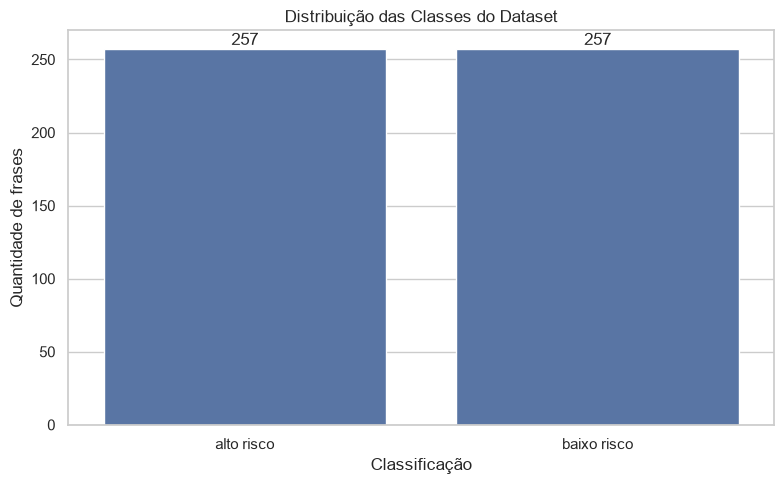

In [5]:
# Contagem de frases por classificação
contagem = df["situacao"].value_counts()

# Gráfico de barras
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contagem.index,
    y=contagem.values
)

plt.title("Distribuição das Classes do Dataset")
plt.xlabel("Classificação")
plt.ylabel("Quantidade de frases")

# Exibir valores sobre as barras
for i, valor in enumerate(contagem.values):
    plt.text(i, valor + 3, str(valor), ha="center")

plt.tight_layout()
plt.show()

A análise da distribuição das classes demonstrou equilíbrio entre as categorias, com 257 registros classificados como alto risco e 257 como baixo risco, representando 50% da amostra para cada classe.

In [6]:
# Contar palavras em cada frase
df["quantidade_palavras"] = df["frase"].apply(
    lambda frase: len(str(frase).split())
)

# Estatísticas gerais
print("===== TAMANHO DAS FRASES =====")
print(df["quantidade_palavras"].describe())

# Comparar por classificação
print("\n===== MÉDIA DE PALAVRAS POR CLASSE =====")
print(
    df.groupby("situacao")["quantidade_palavras"].mean()
)

===== TAMANHO DAS FRASES =====
count    514.000000
mean      11.083658
std        1.713041
min        6.000000
25%       10.000000
50%       11.000000
75%       12.000000
max       17.000000
Name: quantidade_palavras, dtype: float64

===== MÉDIA DE PALAVRAS POR CLASSE =====
situacao
alto risco     11.548638
baixo risco    10.618677
Name: quantidade_palavras, dtype: float64


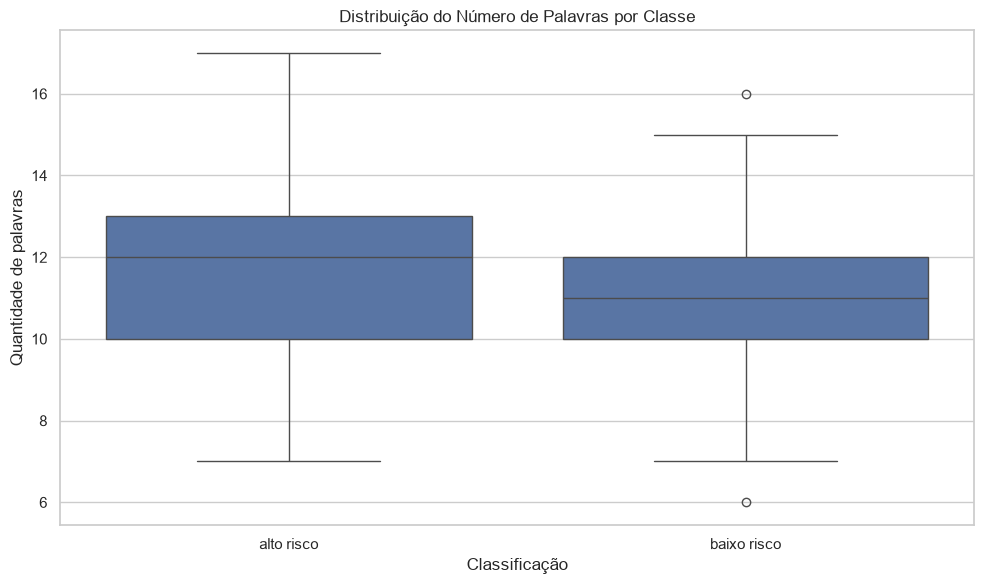

In [7]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="situacao",
    y="quantidade_palavras"
)

plt.title("Distribuição do Número de Palavras por Classe")
plt.xlabel("Classificação")
plt.ylabel("Quantidade de palavras")

plt.tight_layout()
plt.show()

In [8]:
from collections import Counter
import re

# Separar frases por classificação
frases_alto = df[df["situacao"] == "alto risco"]["frase"]
frases_baixo = df[df["situacao"] == "baixo risco"]["frase"]

# Função para contar palavras
def contar_palavras(frases):
    palavras = []

    for frase in frases:
        texto = frase.lower()
        texto = re.sub(r"[^\w\s]", "", texto)
        palavras.extend(texto.split())

    return Counter(palavras)

# Contagem por classe
frequencia_alto = contar_palavras(frases_alto)
frequencia_baixo = contar_palavras(frases_baixo)

print("===== 20 PALAVRAS MAIS FREQUENTES: ALTO RISCO =====")
print(frequencia_alto.most_common(20))

print("\n===== 20 PALAVRAS MAIS FREQUENTES: BAIXO RISCO =====")
print(frequencia_baixo.most_common(20))

===== 20 PALAVRAS MAIS FREQUENTES: ALTO RISCO =====
[('e', 236), ('estou', 131), ('com', 124), ('de', 123), ('uma', 112), ('no', 108), ('peito', 107), ('dor', 83), ('muito', 76), ('está', 65), ('que', 62), ('meu', 61), ('ar', 56), ('sinto', 54), ('forte', 49), ('coração', 49), ('falta', 46), ('pressão', 40), ('a', 39), ('intensa', 36)]

===== 20 PALAVRAS MAIS FREQUENTES: BAIXO RISCO =====
[('de', 158), ('depois', 124), ('uma', 122), ('quando', 105), ('um', 73), ('no', 60), ('sinto', 55), ('peito', 50), ('meu', 46), ('tenho', 45), ('leve', 45), ('mais', 45), ('fico', 42), ('pouco', 38), ('coração', 38), ('vezes', 29), ('minha', 28), ('às', 28), ('estou', 28), ('o', 25)]


In [9]:
# Lista inicial de palavras comuns (stopwords)
stopwords = {
    "e", "de", "da", "do", "das", "dos",
    "a", "o", "as", "os", "um", "uma",
    "uns", "umas", "no", "na", "nos", "nas",
    "com", "sem", "que", "quando", "depois",
    "antes", "estou", "está", "estão",
    "meu", "minha", "meus", "minhas",
    "sinto", "tenho", "fico", "às", "ao",
    "mais", "muito", "pouco", "vezes",
    "por", "para", "em", "é", "foi",
    "ou", "se", "mas", "como", "minha"
}

# Função atualizada
def contar_palavras_filtradas(frases):
    palavras = []

    for frase in frases:
        texto = frase.lower()
        texto = re.sub(r"[^\w\s]", "", texto)

        for palavra in texto.split():
            if palavra not in stopwords:
                palavras.append(palavra)

    return Counter(palavras)


frequencia_alto_filtrada = contar_palavras_filtradas(frases_alto)
frequencia_baixo_filtrada = contar_palavras_filtradas(frases_baixo)

print("===== ALTO RISCO =====")
print(frequencia_alto_filtrada.most_common(20))

print("\n===== BAIXO RISCO =====")
print(frequencia_baixo_filtrada.most_common(20))

===== ALTO RISCO =====
[('peito', 107), ('dor', 83), ('ar', 56), ('forte', 49), ('coração', 49), ('falta', 46), ('pressão', 40), ('intensa', 36), ('respirar', 32), ('sensação', 32), ('tórax', 31), ('suor', 31), ('tontura', 30), ('frio', 29), ('não', 28), ('dificuldade', 25), ('fraqueza', 24), ('palpitações', 23), ('mesmo', 22), ('repente', 20)]

===== BAIXO RISCO =====
[('peito', 50), ('leve', 45), ('coração', 38), ('tórax', 23), ('dor', 22), ('percebo', 22), ('cansaço', 21), ('me', 20), ('respiração', 20), ('região', 19), ('durante', 19), ('rápida', 18), ('muscular', 18), ('fica', 18), ('costelas', 18), ('ofegante', 18), ('acelera', 18), ('cansado', 18), ('batimentos', 17), ('rápido', 16)]


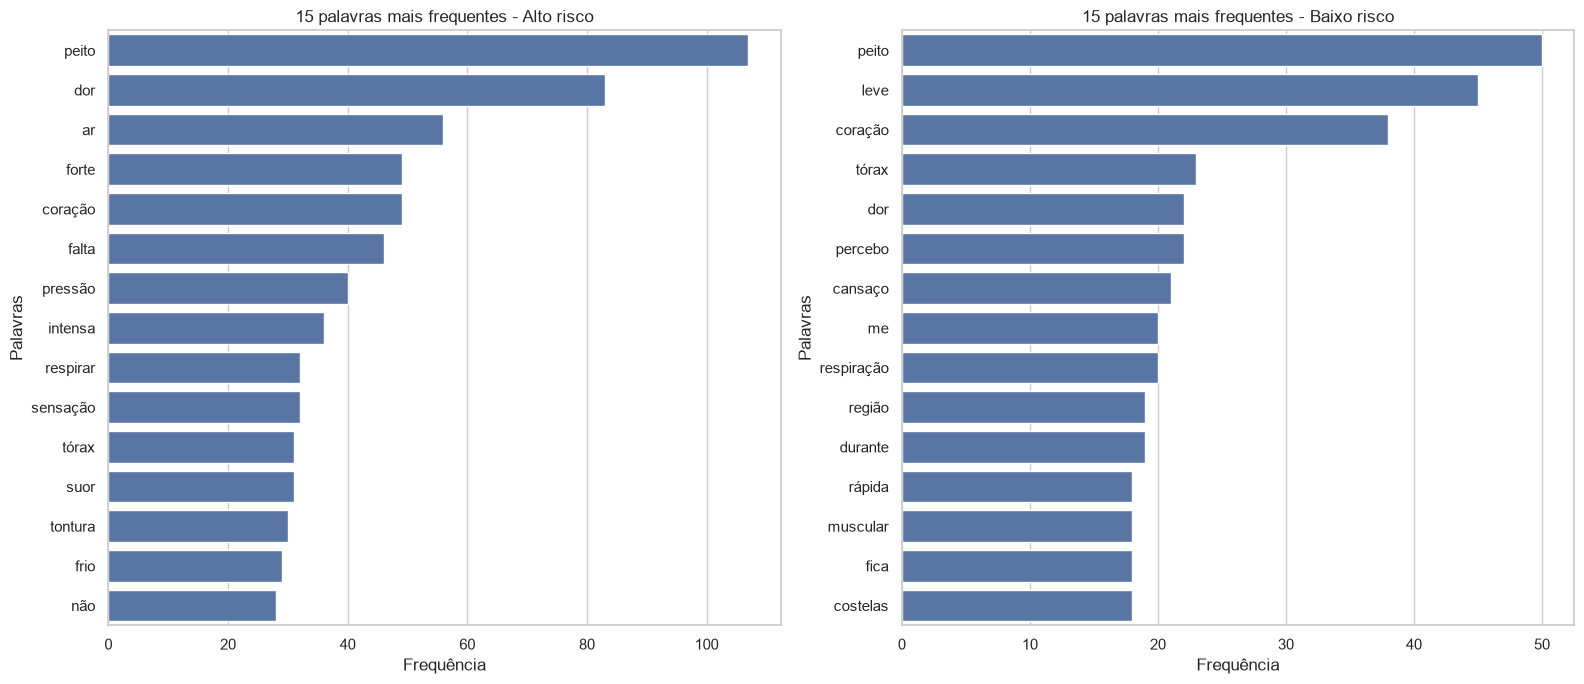

In [10]:
# Preparar dados para os gráficos
top_alto = frequencia_alto_filtrada.most_common(15)
top_baixo = frequencia_baixo_filtrada.most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Gráfico alto risco
palavras_alto, valores_alto = zip(*top_alto)

sns.barplot(
    x=list(valores_alto),
    y=list(palavras_alto),
    ax=axes[0]
)

axes[0].set_title("15 palavras mais frequentes - Alto risco")
axes[0].set_xlabel("Frequência")
axes[0].set_ylabel("Palavras")

# Gráfico baixo risco
palavras_baixo, valores_baixo = zip(*top_baixo)

sns.barplot(
    x=list(valores_baixo),
    y=list(palavras_baixo),
    ax=axes[1]
)

axes[1].set_title("15 palavras mais frequentes - Baixo risco")
axes[1].set_xlabel("Frequência")
axes[1].set_ylabel("Palavras")

plt.tight_layout()
plt.show()

In [11]:
# Total de palavras em cada classe
total_alto = sum(frequencia_alto_filtrada.values())
total_baixo = sum(frequencia_baixo_filtrada.values())

# Unir todas as palavras
todas_palavras = set(frequencia_alto_filtrada) | set(frequencia_baixo_filtrada)

# Criar tabela comparativa
comparacao = pd.DataFrame({
    "palavra": list(todas_palavras),
    "alto_risco": [
        frequencia_alto_filtrada[p] / total_alto
        for p in todas_palavras
    ],
    "baixo_risco": [
        frequencia_baixo_filtrada[p] / total_baixo
        for p in todas_palavras
    ]
})

# Calcular diferença entre as frequências
comparacao["diferenca"] = (
    comparacao["alto_risco"] - comparacao["baixo_risco"]
)

# Ordenar pelas maiores diferenças
comparacao = comparacao.sort_values(
    by="diferenca",
    ascending=False
)

print("===== PALAVRAS MAIS ASSOCIADAS A ALTO RISCO =====")
display(comparacao.head(15))

print("===== PALAVRAS MAIS ASSOCIADAS A BAIXO RISCO =====")
display(comparacao.tail(15).sort_values("diferenca"))

===== PALAVRAS MAIS ASSOCIADAS A ALTO RISCO =====


,palavra,alto_risco,baixo_risco,diferenca
453,dor,0.052565,0.015482,0.037083
362,ar,0.035465,0.000704,0.034762
391,peito,0.067764,0.035186,0.032578
412,falta,0.029132,0.002111,0.027021
119,pressão,0.025332,0.001407,0.023925
257,forte,0.031032,0.008445,0.022588
401,intensa,0.022799,0.001407,0.021392
378,suor,0.019633,0.000000,0.019633
176,tontura,0.018999,0.000000,0.018999
487,respirar,0.020266,0.001407,0.018859


===== PALAVRAS MAIS ASSOCIADAS A BAIXO RISCO =====


,palavra,alto_risco,baixo_risco,diferenca
263,leve,0.000000,0.031668,-0.031668
38,percebo,0.000000,0.015482,-0.015482
424,cansaço,0.000633,0.014778,-0.014145
463,me,0.000633,0.014075,-0.013441
430,região,0.000633,0.013371,-0.012738
382,fica,0.000000,0.012667,-0.012667
444,acelera,0.000000,0.012667,-0.012667
431,costelas,0.000000,0.012667,-0.012667
488,cansado,0.000000,0.012667,-0.012667
116,muscular,0.000000,0.012667,-0.012667


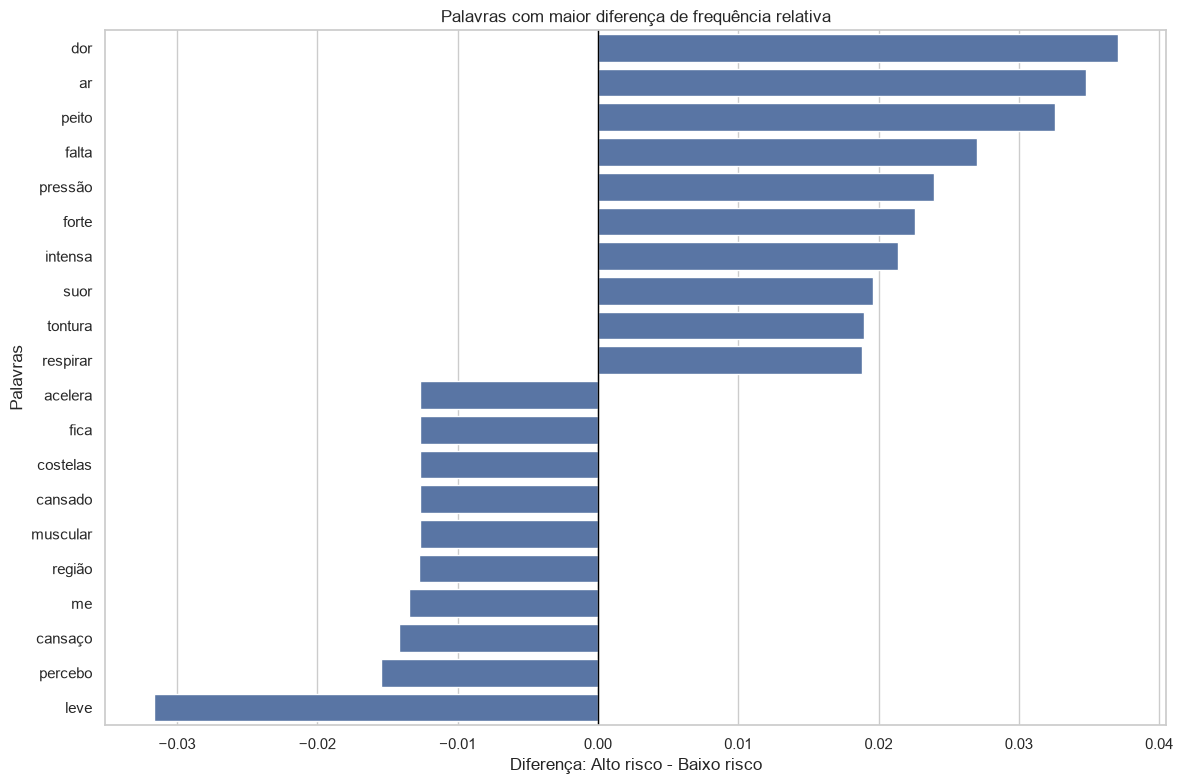

In [12]:
# Selecionar 10 palavras de cada extremo
top_alto = comparacao.head(10)
top_baixo = comparacao.tail(10)

dados_grafico = pd.concat([top_alto, top_baixo])

plt.figure(figsize=(12, 8))

sns.barplot(
    data=dados_grafico,
    x="diferenca",
    y="palavra"
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Palavras com maior diferença de frequência relativa")
plt.xlabel("Diferença: Alto risco - Baixo risco")
plt.ylabel("Palavras")

plt.tight_layout()
plt.show()

### Análise da frequência relativa das palavras

A comparação da frequência relativa entre as classes identificou diferenças no vocabulário utilizado nas frases sintéticas. Na categoria de alto risco, destacaram-se termos como "dor", "ar", "peito", "falta" e "pressão". Já na categoria de baixo risco, destacaram-se palavras como "leve", "percebo", "cansaço", "muscular" e "costelas".

Os resultados demonstram que existem padrões lexicais distintos entre as duas categorias, que poderão ser explorados durante o treinamento do modelo de classificação.

Entretanto, a presença isolada de uma palavra não é suficiente para determinar a classe de uma frase. O contexto textual deve ser considerado, e os padrões identificados refletem exclusivamente a composição do dataset sintético, não constituindo evidência ou validação clínica.

## Preparação dos dados para Machine Learning


In [13]:
from sklearn.model_selection import train_test_split

# Separar as frases (X) e as classificações (y)
X = df["frase"]
y = df["situacao"]

# Dividir em treinamento e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Quantidade de frases para treinamento:", len(X_treino))
print("Quantidade de frases para teste:", len(X_teste))

print("\nDistribuição no treinamento:")
print(y_treino.value_counts())

print("\nDistribuição no teste:")
print(y_teste.value_counts())

Quantidade de frases para treinamento: 411
Quantidade de frases para teste: 103

Distribuição no treinamento:
situacao
baixo risco    206
alto risco     205
Name: count, dtype: int64

Distribuição no teste:
situacao
alto risco     52
baixo risco    51
Name: count, dtype: int64


## Vetorização dos textos com TF-IDF

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Criar o vetorizador
vetorizador = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=1000
)

# Aprender o vocabulário somente com os dados de treinamento
X_treino_tfidf = vetorizador.fit_transform(X_treino)

# Transformar os dados de teste usando o mesmo vocabulário
X_teste_tfidf = vetorizador.transform(X_teste)

print("Formato da matriz de treinamento:", X_treino_tfidf.shape)
print("Formato da matriz de teste:", X_teste_tfidf.shape)

print("\nQuantidade de palavras e combinações aprendidas:")
print(len(vetorizador.get_feature_names_out()))

Formato da matriz de treinamento: (411, 1000)
Formato da matriz de teste: (103, 1000)

Quantidade de palavras e combinações aprendidas:
1000


Organização dos números

In [15]:
# Converter uma pequena amostra da matriz para DataFrame
amostra_tfidf = pd.DataFrame(
    X_treino_tfidf[:5].toarray(),
    columns=vetorizador.get_feature_names_out()
)

display(amostra_tfidf.iloc[:, :15].round(3))

,academia,academia fiquei,academia normaliza,acelera,acelera durante,acelera por,acelera quando,acelera um,acelerada,acelerada depois,acelerada durante,acelerada quando,acelerado,acelerado demais,acelerado falta
0,0.32,0.359,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.00,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.00,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.00,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.00,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Quais características são mais relevantes

In [16]:
# Listar características do vocabulário
caracteristicas = vetorizador.get_feature_names_out()

print("Primeiras 30 características:")
print(caracteristicas[:30])

Primeiras 30 características:
['academia' 'academia fiquei' 'academia normaliza' 'acelera'
 'acelera durante' 'acelera por' 'acelera quando' 'acelera um' 'acelerada'
 'acelerada depois' 'acelerada durante' 'acelerada quando' 'acelerado'
 'acelerado demais' 'acelerado falta' 'acelerado há' 'acelerados'
 'acelerar' 'aceleração' 'aceleração dos' 'acelerou' 'acompanhada'
 'acompanhada de' 'acompanhadas' 'acompanhadas de' 'aeróbicos' 'algo'
 'alguma' 'algumas' 'algumas batidas']


## Primeiro modelo de classificação — Regressão Logística

In [17]:
from sklearn.linear_model import LogisticRegression

# Criar o modelo
modelo_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Treinar o modelo
modelo_lr.fit(X_treino_tfidf, y_treino)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [18]:
# Realizar previsões com os dados de teste
y_pred = modelo_lr.predict(X_teste_tfidf)

print("Primeiras 10 previsões:")
print(y_pred[:10])

print("\nClassificações reais:")
print(y_teste.iloc[:10].values)

Primeiras 10 previsões:
['alto risco' 'alto risco' 'alto risco' 'alto risco' 'alto risco'
 'baixo risco' 'baixo risco' 'alto risco' 'alto risco' 'alto risco']

Classificações reais:
<StringArray>
[ 'alto risco',  'alto risco',  'alto risco',  'alto risco',  'alto risco',
 'baixo risco', 'baixo risco',  'alto risco',  'alto risco',  'alto risco']
Length: 10, dtype: str


## Avaliação do modelo — Regressão Logística

In [19]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calcular acurácia
acuracia = accuracy_score(y_teste, y_pred)

print(f"Acurácia: {acuracia:.4f}")
print(f"Acurácia em porcentagem: {acuracia * 100:.2f}%")

# Relatório de classificação
print("\nRelatório de classificação:")
print(classification_report(y_teste, y_pred))

# Matriz de confusão
print("\nMatriz de confusão:")
print(confusion_matrix(
    y_teste,
    y_pred,
    labels=["baixo risco", "alto risco"]
))

Acurácia: 1.0000
Acurácia em porcentagem: 100.00%

Relatório de classificação:
              precision    recall  f1-score   support

  alto risco       1.00      1.00      1.00        52
 baixo risco       1.00      1.00      1.00        51

    accuracy                           1.00       103
   macro avg       1.00      1.00      1.00       103
weighted avg       1.00      1.00      1.00       103


Matriz de confusão:
[[51  0]
 [ 0 52]]


## Investigação de similaridade entre treino e teste

In [25]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Comparar cada frase de teste com todas as frases de treinamento
similaridades = cosine_similarity(
    X_teste_tfidf,
    X_treino_tfidf
)

# Encontrar a maior similaridade para cada frase de teste
maiores_similaridades = similaridades.max(axis=1)

print("Similaridade média:", round(maiores_similaridades.mean(), 4))
print("Maior similaridade:", round(maiores_similaridades.max(), 4))
print("Frases com similaridade >= 0.80:",
      np.sum(maiores_similaridades >= 0.80))
print("Frases com similaridade >= 0.90:",
      np.sum(maiores_similaridades >= 0.90))

Similaridade média: 0.5589
Maior similaridade: 1.0
Frases com similaridade >= 0.80: 6
Frases com similaridade >= 0.90: 2


Modelo 01 — Regressão Logística + TF-IDF
- Dataset: 514 frases sintéticas.
- Treinamento: 411 frases.
- Teste: 103 frases.
- Acurácia experimental: 100%.
- Falsos positivos e falsos negativos: zero.

In [26]:
# Encontrar o índice da frase de treinamento mais semelhante
indices_mais_proximos = similaridades.argmax(axis=1)

# Criar relatório
relatorio_proximidade = pd.DataFrame({
    "frase_teste": X_teste.values,
    "classe_teste": y_teste.values,
    "frase_treinamento": X_treino.iloc[
        indices_mais_proximos
    ].values,
    "classe_treinamento": y_treino.iloc[
        indices_mais_proximos
    ].values,
    "similaridade": maiores_similaridades
})

# Mostrar somente os casos com similaridade >= 0.80
casos_proximos = (
    relatorio_proximidade[
        relatorio_proximidade["similaridade"] >= 0.80
    ]
    .sort_values("similaridade", ascending=False)
)

display(casos_proximos)


,frase_teste,classe_teste,frase_treinamento,classe_treinamento,similaridade
42,Tenho palpitações ocasionais em situações de e...,baixo risco,Tenho palpitações leves e passageiras em momen...,baixo risco,1.000000
51,Percebo algumas batidas fortes depois de uma n...,baixo risco,Percebo algumas batidas mais fortes depois de ...,baixo risco,0.926951
28,Meu coração está batendo de forma irregular e ...,alto risco,Meu coração está batendo de forma irregular e ...,alto risco,0.887232
70,Sinto um cansaço leve depois de caminhar por b...,baixo risco,Depois de caminhar por bastante tempo sinto um...,baixo risco,0.861322
91,Minha respiração fica mais profunda depois de ...,baixo risco,Minha respiração fica mais profunda depois de ...,baixo risco,0.842652
72,Uma dor repentina no peito veio acompanhada de...,alto risco,Uma dor repentina e intensa no peito veio acom...,alto risco,0.820797


In [27]:
# Verificar se as frases mais próximas são exatamente iguais
casos_proximos = casos_proximos.copy()

casos_proximos["textos_identicos"] = (
    casos_proximos["frase_teste"]
    == casos_proximos["frase_treinamento"]
)

display(
    casos_proximos[
        [
            "frase_teste",
            "frase_treinamento",
            "similaridade",
            "textos_identicos"
        ]
    ]
)

,frase_teste,frase_treinamento,similaridade,textos_identicos
42,Tenho palpitações ocasionais em situações de e...,Tenho palpitações leves e passageiras em momen...,1.000000,False
51,Percebo algumas batidas fortes depois de uma n...,Percebo algumas batidas mais fortes depois de ...,0.926951,False
28,Meu coração está batendo de forma irregular e ...,Meu coração está batendo de forma irregular e ...,0.887232,False
70,Sinto um cansaço leve depois de caminhar por b...,Depois de caminhar por bastante tempo sinto um...,0.861322,False
91,Minha respiração fica mais profunda depois de ...,Minha respiração fica mais profunda depois de ...,0.842652,False
72,Uma dor repentina no peito veio acompanhada de...,Uma dor repentina e intensa no peito veio acom...,0.820797,False


In [28]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Calcula a similaridade entre todas as frases
similaridade_total = cosine_similarity(
    vetorizador.transform(df["frase"])
)

# Evita comparar cada frase com ela mesma
np.fill_diagonal(similaridade_total, 0)

# Localiza pares com similaridade igual ou superior a 0.80
linha, coluna = np.where(
    np.triu(similaridade_total >= 0.80, k=1)
)

pares_dataset = pd.DataFrame({
    "frase_1": df.iloc[linha]["frase"].values,
    "classe_1": df.iloc[linha]["situacao"].values,
    "frase_2": df.iloc[coluna]["frase"].values,
    "classe_2": df.iloc[coluna]["situacao"].values,
    "similaridade": similaridade_total[linha, coluna]
})

pares_dataset = pares_dataset.sort_values(
    "similaridade",
    ascending=False
)

print("Quantidade de pares semelhantes:", len(pares_dataset))

display(pares_dataset)

Quantidade de pares semelhantes: 17


,frase_1,classe_1,frase_2,classe_2,similaridade
11,Tenho palpitações leves e passageiras em momen...,baixo risco,Tenho palpitações ocasionais em situações de e...,baixo risco,1.000000
13,"Depois de uma caminhada, noto os batimentos ma...",baixo risco,"Depois de uma caminhada, percebo os batimentos...",baixo risco,0.939592
12,Percebo algumas batidas mais fortes depois de ...,baixo risco,Percebo algumas batidas fortes depois de uma n...,baixo risco,0.926951
5,Às vezes suspiro fundo quando estou cansado,baixo risco,Às vezes suspiro fundo quando estou cansado ou...,baixo risco,0.907644
16,Meu coração acelera um pouco quando fico empol...,baixo risco,Meu coração acelera um pouco quando fico empol...,baixo risco,0.898585
8,Meu coração está batendo de forma irregular e ...,alto risco,Meu coração está batendo de forma irregular e ...,alto risco,0.887232
9,"Sinto o coração muito forte, falta de ar e ton...",alto risco,"Estou com palpitação muito forte, falta de ar ...",alto risco,0.870901
15,Às vezes sinto uma batida mais forte no peito ...,baixo risco,Às vezes percebo uma batida mais forte no peit...,baixo risco,0.864748
3,Sinto um cansaço leve depois de caminhar por b...,baixo risco,Depois de caminhar por bastante tempo sinto um...,baixo risco,0.861322
14,"Estou com enjoo, dor no tórax e sensação de qu...",alto risco,"Estou com dor no tórax, enjoo e sensação de qu...",alto risco,0.851776


Identificar os grupos de frases semelhantes

In [29]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

# Cria uma matriz de conexões entre frases semelhantes
limite_similaridade = 0.80

conexoes = similaridade_total >= limite_similaridade

# Garante que as conexões sejam simétricas
conexoes = conexoes | conexoes.T

# Identifica os grupos conectados
matriz_conexoes = csr_matrix(conexoes)

quantidade_grupos, identificadores_grupos = connected_components(
    matriz_conexoes,
    directed=False
)

# Adiciona o identificador de grupo ao dataset
df_grupos = df.copy()
df_grupos["grupo"] = identificadores_grupos

# Exibe somente grupos com mais de uma frase
grupos_semelhantes = (
    df_grupos.groupby("grupo")
    .filter(lambda grupo: len(grupo) > 1)
    .sort_values("grupo")
)

print("Quantidade total de grupos:", quantidade_grupos)
print(
    "Quantidade de frases em grupos semelhantes:",
    len(grupos_semelhantes)
)

display(
    grupos_semelhantes[
        ["grupo", "frase", "situacao"]
    ]
)

Quantidade total de grupos: 497
Quantidade de frases em grupos semelhantes: 34


,grupo,frase,situacao
40,40,Uma dor repentina e intensa no peito veio acom...,alto risco
91,40,Uma dor repentina no peito veio acompanhada de...,alto risco
71,71,Minha musculatura do peito está sensível depoi...,baixo risco
450,71,Minha musculatura do peito está sensível depoi...,baixo risco
460,152,Fico um pouco cansado depois de subir vários l...,baixo risco
153,152,Fico um pouco ofegante depois de subir vários ...,baixo risco
155,154,Sinto um cansaço leve depois de caminhar por b...,baixo risco
452,154,Depois de caminhar por bastante tempo sinto um...,baixo risco
161,160,Fico um pouco ofegante depois de carregar saco...,baixo risco
508,160,Fico um pouco ofegante depois de brincar com m...,baixo risco


Quantos grupos distintos existem e quantas frases estão envolvidas.

In [30]:
# Identifica grupos com mais de uma frase
resumo_grupos = (
    grupos_semelhantes
    .groupby("grupo")
    .agg(
        quantidade_frases=("frase", "count"),
        quantidade_classes=("situacao", "nunique"),
        classes=("situacao", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

print("Quantidade de grupos semelhantes:", len(resumo_grupos))

print(
    "Quantidade total de frases nesses grupos:",
    resumo_grupos["quantidade_frases"].sum()
)

print(
    "Grupos com mais de duas frases:",
    (resumo_grupos["quantidade_frases"] > 2).sum()
)

print(
    "Grupos com classes diferentes:",
    (resumo_grupos["quantidade_classes"] > 1).sum()
)

display(resumo_grupos)

Quantidade de grupos semelhantes: 17
Quantidade total de frases nesses grupos: 34
Grupos com mais de duas frases: 0
Grupos com classes diferentes: 0


,grupo,quantidade_frases,quantidade_classes,classes
0,40,2,1,alto risco
1,71,2,1,baixo risco
2,152,2,1,baixo risco
3,154,2,1,baixo risco
4,160,2,1,baixo risco
5,165,2,1,baixo risco
6,186,2,1,baixo risco
7,189,2,1,baixo risco
8,197,2,1,alto risco
9,222,2,1,alto risco


## Validação com separação por grupos

In [31]:
from sklearn.model_selection import StratifiedGroupKFold

# Recupera os dados e os grupos identificados
X_grupos = df_grupos["frase"]
y_grupos = df_grupos["situacao"]
grupos = df_grupos["grupo"]

# Configura a divisão em 5 partes
divisor_grupos = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Separa treinamento e teste
for indices_treino, indices_teste in divisor_grupos.split(
    X_grupos,
    y_grupos,
    groups=grupos
):
    break

# Cria os conjuntos
X_treino_grupo = X_grupos.iloc[indices_treino]
X_teste_grupo = X_grupos.iloc[indices_teste]

y_treino_grupo = y_grupos.iloc[indices_treino]
y_teste_grupo = y_grupos.iloc[indices_teste]

print("Total de frases:", len(df_grupos))
print("Treinamento:", len(X_treino_grupo))
print("Teste:", len(X_teste_grupo))

print("\nDistribuição no treinamento:")
print(y_treino_grupo.value_counts())

print("\nDistribuição no teste:")
print(y_teste_grupo.value_counts())

Total de frases: 514
Treinamento: 411
Teste: 103

Distribuição no treinamento:
situacao
alto risco     206
baixo risco    205
Name: count, dtype: int64

Distribuição no teste:
situacao
baixo risco    52
alto risco     51
Name: count, dtype: int64


Conferência se o grupos foram separados corretamente

In [32]:
grupos_treino = set(
    grupos.iloc[indices_treino]
)

grupos_teste = set(
    grupos.iloc[indices_teste]
)

grupos_em_comum = grupos_treino.intersection(
    grupos_teste
)

print("Grupos no treinamento:", len(grupos_treino))
print("Grupos no teste:", len(grupos_teste))
print("Grupos presentes nos dois conjuntos:", len(grupos_em_comum))

Grupos no treinamento: 398
Grupos no teste: 99
Grupos presentes nos dois conjuntos: 0


## Treinamento do novo modelo

In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Criar um novo vetorizador
vetorizador_grupo = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=1000
)

# Aprender o vocabulário somente com treinamento
X_treino_grupo_tfidf = vetorizador_grupo.fit_transform(
    X_treino_grupo
)

# Transformar os dados de teste
X_teste_grupo_tfidf = vetorizador_grupo.transform(
    X_teste_grupo
)

# Criar e treinar o modelo
modelo_lr_grupo = LogisticRegression(
    max_iter=1000,
    random_state=42
)

modelo_lr_grupo.fit(
    X_treino_grupo_tfidf,
    y_treino_grupo
)

# Realizar previsões
y_pred_grupo = modelo_lr_grupo.predict(
    X_teste_grupo_tfidf
)

print("Novo treinamento concluído!")

Novo treinamento concluído!


Avaliação do modelo criado

In [34]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

acuracia_grupo = accuracy_score(
    y_teste_grupo,
    y_pred_grupo
)

print(f"Acurácia: {acuracia_grupo:.4f}")
print(f"Porcentagem: {acuracia_grupo * 100:.2f}%")

print("\nRelatório de classificação:")
print(classification_report(y_teste_grupo, y_pred_grupo))

print("\nMatriz de confusão:")
print(confusion_matrix(
    y_teste_grupo,
    y_pred_grupo,
    labels=["baixo risco", "alto risco"]
))

Acurácia: 0.9903
Porcentagem: 99.03%

Relatório de classificação:
              precision    recall  f1-score   support

  alto risco       1.00      0.98      0.99        51
 baixo risco       0.98      1.00      0.99        52

    accuracy                           0.99       103
   macro avg       0.99      0.99      0.99       103
weighted avg       0.99      0.99      0.99       103


Matriz de confusão:
[[52  0]
 [ 1 50]]


Conclusão até agora: 

-A Regressão Logística apresentou desempenho elevado nas duas avaliações.

-A separação por grupos reduziu a possibilidade de avaliação favorecida por paráfrases próximas.

-O modelo ainda apresentou um erro na identificação de alto risco, demonstrando que a acurácia isolada não é suficiente para avaliar o sistema.

Investigação do erro cometido

In [35]:
# Identificar previsões incorretas
erros = X_teste_grupo[
    y_teste_grupo.values != y_pred_grupo
]

# Criar relatório dos erros
relatorio_erros = pd.DataFrame({
    "frase": erros.values,
    "classe_real": y_teste_grupo.loc[erros.index].values,
    "classe_prevista": y_pred_grupo[
        y_teste_grupo.values != y_pred_grupo
    ]
})

display(relatorio_erros)

,frase,classe_real,classe_prevista
0,Uma dor no peito apareceu durante uma caminhad...,alto risco,baixo risco


Analisar os pesos das palavras

In [36]:
# Recuperar os coeficientes aprendidos pelo modelo
nomes_palavras = vetorizador_grupo.get_feature_names_out()

coeficientes = modelo_lr_grupo.coef_[0]

# Organizar os pesos em uma tabela
pesos_palavras = pd.DataFrame({
    "palavra": nomes_palavras,
    "peso": coeficientes
})

# Ordenar pelos maiores pesos positivos
mais_associadas_alto = pesos_palavras.sort_values(
    "peso",
    ascending=False
).head(20)

# Ordenar pelos maiores pesos negativos
mais_associadas_baixo = pesos_palavras.sort_values(
    "peso",
    ascending=True
).head(20)

print("Palavras mais associadas a alto risco:")
display(mais_associadas_alto)

print("Palavras mais associadas a baixo risco:")
display(mais_associadas_baixo)

Palavras mais associadas a alto risco:


,palavra,peso
787,quando,2.331280
221,depois,1.969680
222,depois de,1.918314
937,um,1.170124
544,leve,1.118378
560,mais,1.098734
791,quando estou,1.016841
946,um pouco,0.900933
758,pouco,0.894625
277,durante,0.793135


Palavras mais associadas a baixo risco:


,palavra,peso
609,muito,-1.603632
309,estou,-1.528511
127,com,-1.468998
312,estou com,-1.398912
321,está,-1.368073
58,ar,-1.269312
259,dor,-1.195257
188,de ar,-0.981274
774,pressão,-0.975805
503,intensa,-0.964195


In [37]:
# Recuperar a frase que foi classificada incorretamente
frase_erro = erros.iloc[0]

# Transformar a frase usando o vetorizador treinado
frase_tfidf = vetorizador_grupo.transform([frase_erro])

# Recuperar os termos presentes na frase
indices = frase_tfidf.nonzero()[1]

# Criar tabela com contribuição de cada termo
contribuicoes = pd.DataFrame({
    "palavra": nomes_palavras[indices],
    "valor_tfidf": frase_tfidf.toarray()[0][indices],
    "peso_modelo": coeficientes[indices]
})

contribuicoes["contribuicao"] = (
    contribuicoes["valor_tfidf"] *
    contribuicoes["peso_modelo"]
)

contribuicoes = contribuicoes.sort_values(
    "contribuicao",
    ascending=False
)

display(contribuicoes)

,palavra,valor_tfidf,peso_modelo,contribuicao
11,quando,0.170720,2.331280,0.397995
4,durante,0.272376,0.793135,0.216031
1,caminhada,0.330171,0.286000,0.094429
5,durante uma,0.361574,0.258938,0.093625
12,uma,0.247287,0.362318,0.089597
13,uma caminhada,0.339093,0.239107,0.081080
0,apareceu,0.283859,-0.203445,-0.057750
10,peito apareceu,0.339093,-0.219259,-0.074349
6,no,0.141860,-0.545082,-0.077325
7,no peito,0.173064,-0.635153,-0.109922


In [38]:
# Calcular a pontuação bruta do modelo
pontuacao = modelo_lr_grupo.decision_function(
    frase_tfidf
)[0]

# Calcular a probabilidade estimada
probabilidades = modelo_lr_grupo.predict_proba(
    frase_tfidf
)[0]

print("Classes do modelo:", modelo_lr_grupo.classes_)
print("Pontuação da decisão:", round(pontuacao, 4))
print("Intercepto:", round(modelo_lr_grupo.intercept_[0], 4))

print("\nProbabilidades:")
for classe, probabilidade in zip(
    modelo_lr_grupo.classes_,
    probabilidades
):
    print(f"{classe}: {probabilidade:.4f}")

Classes do modelo: ['alto risco' 'baixo risco']
Pontuação da decisão: 0.0259
Intercepto: 0.2507

Probabilidades:
alto risco: 0.4935
baixo risco: 0.5065


In [39]:
print("Frase original:")
print(repr(frase_erro))

print("\nTermos efetivamente presentes:")
print(vetorizador_grupo.get_feature_names_out()[
    frase_tfidf.nonzero()[1]
])

Frase original:
'Uma dor no peito apareceu durante uma caminhada e não passou quando parei'

Termos efetivamente presentes:
['apareceu' 'caminhada' 'dor' 'dor no' 'durante' 'durante uma' 'no'
 'no peito' 'não' 'peito' 'peito apareceu' 'quando' 'uma' 'uma caminhada'
 'uma dor']


Conferir a contribuição total

In [40]:
soma_contribuicoes = contribuicoes["contribuicao"].sum()

print("Soma das contribuições:", round(soma_contribuicoes, 4))
print("Intercepto:", round(modelo_lr_grupo.intercept_[0], 4))
print(
    "Pontuação calculada:",
    round(soma_contribuicoes + modelo_lr_grupo.intercept_[0], 4)
)
print(
    "Pontuação do modelo:",
    round(modelo_lr_grupo.decision_function(frase_tfidf)[0], 4)
)

Soma das contribuições: -0.2248
Intercepto: 0.2507
Pontuação calculada: 0.0259
Pontuação do modelo: 0.0259


In [41]:
frases_teste = [
    "Uma dor no peito apareceu durante uma caminhada e não passou quando parei",
    "Uma dor leve no peito apareceu durante uma caminhada e passou quando parei",
    "Senti dor no peito durante uma caminhada e continuei sentindo depois",
    "Senti um desconforto leve no peito depois de uma caminhada e passou rapidamente"
]

matriz_teste = vetorizador_grupo.transform(frases_teste)

previsoes = modelo_lr_grupo.predict(matriz_teste)
probabilidades = modelo_lr_grupo.predict_proba(matriz_teste)

resultado_teste = pd.DataFrame({
    "frase": frases_teste,
    "previsao": previsoes,
    "prob_alto_risco": probabilidades[:, 0],
    "prob_baixo_risco": probabilidades[:, 1]
})

resultado_teste

,frase,previsao,prob_alto_risco,prob_baixo_risco
0,Uma dor no peito apareceu durante uma caminhad...,baixo risco,0.493518,0.506482
1,Uma dor leve no peito apareceu durante uma cam...,baixo risco,0.301786,0.698214
2,Senti dor no peito durante uma caminhada e con...,baixo risco,0.417580,0.582420
3,Senti um desconforto leve no peito depois de u...,baixo risco,0.135785,0.864215


In [42]:
vetorizador_3gramas = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 3),
    max_features=2000
)

X_treino_3gramas = vetorizador_3gramas.fit_transform(
    X_treino_grupo
)

X_teste_3gramas = vetorizador_3gramas.transform(
    X_teste_grupo
)

modelo_3gramas = LogisticRegression(
    max_iter=1000,
    random_state=42
)

modelo_3gramas.fit(
    X_treino_3gramas,
    y_treino_grupo
)

y_pred_3gramas = modelo_3gramas.predict(X_teste_3gramas)

print("Acurácia:", round(
    modelo_3gramas.score(X_teste_3gramas, y_teste_grupo), 4
))

Acurácia: 1.0


In [44]:
matriz_3gramas = vetorizador_3gramas.transform(frases_teste)

previsoes_3gramas = modelo_3gramas.predict(matriz_3gramas)
probabilidades_3gramas = modelo_3gramas.predict_proba(matriz_3gramas)

resultado_3gramas = pd.DataFrame({
    "frase": frases_teste,
    "previsao": previsoes_3gramas,
    "prob_alto_risco": probabilidades_3gramas[:, 0],
    "prob_baixo_risco": probabilidades_3gramas[:, 1]
})

resultado_3gramas

,frase,previsao,prob_alto_risco,prob_baixo_risco
0,Uma dor no peito apareceu durante uma caminhad...,alto risco,0.536604,0.463396
1,Uma dor leve no peito apareceu durante uma cam...,baixo risco,0.324787,0.675213
2,Senti dor no peito durante uma caminhada e con...,baixo risco,0.469551,0.530449
3,Senti um desconforto leve no peito depois de u...,baixo risco,0.146974,0.853026


Avaliando o modelo

              precision    recall  f1-score   support

 baixo risco       1.00      1.00      1.00        52
  alto risco       1.00      1.00      1.00        51

    accuracy                           1.00       103
   macro avg       1.00      1.00      1.00       103
weighted avg       1.00      1.00      1.00       103



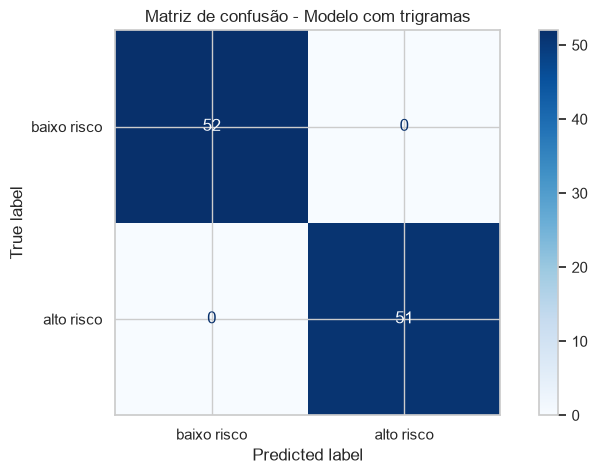

In [45]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print(classification_report(
    y_teste_grupo,
    y_pred_3gramas,
    labels=["baixo risco", "alto risco"],
    zero_division=0
))

matriz = confusion_matrix(
    y_teste_grupo,
    y_pred_3gramas,
    labels=["baixo risco", "alto risco"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["baixo risco", "alto risco"]
)

disp.plot(cmap="Blues")
plt.title("Matriz de confusão - Modelo com trigramas")
plt.show()
